# 38. Horizontal components: orientation, Love waves, Rayleigh ellipticity and a joint velocity model

Notebook 36 used only the verticals. This notebook adds the Trillium horizontals:

1. **Orientation.** The H1/H2 components are not oriented by the data's metadata. Because the source location is
   known, the explosion itself can test the orientation: principal horizontal axes in several windows, and
   whether rotating to radial/transverse separates Rayleigh energy (radial, matching the vertical's
   dispersion) from Love energy (transverse, a distinct curve). B20's two horizontals turn out to be the same
   signal.
2. **Dispersion and ellipticity** on vertical, radial and transverse (multiple-filter analysis as in
   notebook 36), and the Rayleigh H/V amplitude ratio along the fundamental-mode ridge.
3. **A joint model:** three layers over a half-space fitted to the Rayleigh and Love group velocities and the
   P first arrivals (fit C), and also to the H/V ratio (fit D), by differential evolution. Forward modelling
   uses `ksclib.surfacewaves` with `disba`.

Assumptions: Vp = max(1600 m/s, 1.9 Vs) in every layer (water-saturated sediment, or rock with
Vp/Vs = 1.9), and densities rise with depth (1800, 1950, 2100, 2250 kg/m³). The other caveats of notebook 36
apply, and this notebook needs notebooks 26 and 28 (their output CSVs).

Output (`cfg.OUT_DIR / "38_horizontal_components"`): `horizontal_orientation.csv`, `horizontal_correlation_2026.csv`,
`dispersion_ZRT.csv`, `joint_data.csv`, `joint_ensemble.csv` (five optima per fit), `best_model_C.csv`, `best_model_D.csv`,
`ftan_ZRT.png`, `joint_model.png`.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import hilbert
from scipy.optimize import minimize
from obspy import UTCDateTime

from ksclib import surfacewaves as sw
import newglenn_config as cfg

warnings.filterwarnings('ignore', message='ObsPy can not map unit')
assert sw._disba is not None, 'this notebook needs disba (Love waves and ellipticity)'
ORIGIN = cfg.ORIGIN
OUT = cfg.output_dir('38_horizontal_components')
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False})
air = cfg.airwave_speeds()
raw = cfg.event_stream_raw(starttime=ORIGIN - 300, endtime=ORIGIN + 300)
st = cfg.instrument_correct(raw).select(channel='?H?')
picks = pd.read_csv(cfg.OUT_DIR / '26_seismic_arrivals' / 'seismic_picks.csv').set_index('station')
lay = pd.read_csv(cfg.OUT_DIR / '28_air_ground_coupling' / 'layer_resonance.csv')
F0 = lay[lay.pair.str[:3].isin(['B14', 'B29', 'B05'])].groupby(lay.pair.str[:3]).f0_hz.first()
F0_OBS, F0_SIG = float(F0.mean()), max(float(F0.std()), 0.5)

/Users/glennthompson/Developer/KSCRocketSeismoHydrology/.claude/worktrees/newglenn-paper-7faf3d/ksclib/src/ksclib/centaur.py:136: UserWarning: B14: no Centaur response before 2026-05-29T01:00:02.370000Z; using 1R.B14_20260614T135243Z.xml (16.5 days later)
  warnings.warn(str(m.message))


## 1. Orientation

**B20.** Its HH1 and HH2 correlate at 0.9999 in raw counts, in pre-event noise and on every day sampled from
February to August 2026 (at both sampling rates). They are one signal recorded twice, so B20's horizontals
are unusable; with B20's noisy vertical and its reversed coupling sign (notebook 28), B20's Trillium should
be checked in the field.

**B14 and B29.** For each window: the principal horizontal axis (angle from CH1 towards CH2), its
linearity (1 − λ₂/λ₁), and the CH1 azimuth implied if that axis is the source-station (radial) direction
(modulo 180°).

In [2]:
def paxis(h1, h2):
    w, v = np.linalg.eigh(np.cov(np.vstack([h1, h2])))
    return np.degrees(np.arctan2(v[1, 1], v[0, 1])) % 180, 1 - w[0] / w[1]

rows = []
for sta in ('B20', 'B14', 'B29'):
    h1r = raw.select(station=sta, channel='?H1')[0].slice(ORIGIN - 250, ORIGIN - 20).data.astype(float)
    h2r = raw.select(station=sta, channel='?H2')[0].slice(ORIGIN - 250, ORIGIN - 20).data.astype(float)
    n = min(len(h1r), len(h2r))
    r12 = np.corrcoef(h1r[:n], h2r[:n])[0, 1]
    h1, h2 = st.select(station=sta, channel='?H1')[0], st.select(station=sta, channel='?H2')[0]
    ta, rad = air.travel_time_s[sta], air.azimuth_deg[sta]
    for lab, band, w in (('airwave 0-1.5 s, 1-10 Hz', (1, 10), (ta, ta + 1.5)),
                         ('Rayleigh 1-3 Hz', (1, 3), (10, ta - 5)), ('Rayleigh 0.5-1.5 Hz', (0.5, 1.5), (8, ta - 5)),
                         ('first 5-12 s, 2-8 Hz', (2, 8), (5, 12)), ('pre-event noise, 1-10 Hz', (1, 10), (-120, -20))):
        x = [t.copy().filter('bandpass', freqmin=band[0], freqmax=band[1], corners=4, zerophase=True)
             .slice(ORIGIN + w[0], ORIGIN + w[1]).data for t in (h1, h2)]
        m = min(map(len, x))
        a, lin = paxis(x[0][:m], x[1][:m])
        rows.append(dict(station=sta, raw_noise_corr_H1_H2=r12, window=lab, axis_from_H1_deg=a, linearity=lin,
                         H1_azimuth_if_radial=(rad - a) % 180))
ori = pd.DataFrame(rows)
ori.to_csv(OUT / 'horizontal_orientation.csv', index=False)
display(ori.round(2))

,station,raw_noise_corr_H1_H2,window,axis_from_H1_deg,linearity,H1_azimuth_if_radial
0,B20,1.00,"airwave 0-1.5 s, 1-10 Hz",47.32,1.00,118.26
1,B20,1.00,Rayleigh 1-3 Hz,46.55,1.00,119.03
2,B20,1.00,Rayleigh 0.5-1.5 Hz,46.60,1.00,118.97
3,B20,1.00,"first 5-12 s, 2-8 Hz",46.55,1.00,119.03
4,B20,1.00,"pre-event noise, 1-10 Hz",46.66,1.00,118.92
5,B14,0.27,"airwave 0-1.5 s, 1-10 Hz",19.15,0.79,138.96
6,B14,0.27,Rayleigh 1-3 Hz,161.21,0.46,176.90
7,B14,0.27,Rayleigh 0.5-1.5 Hz,53.28,0.39,104.83
8,B14,0.27,"first 5-12 s, 2-8 Hz",126.35,0.65,31.76
9,B14,0.27,"pre-event noise, 1-10 Hz",75.14,0.49,82.97


### B20's horizontals through the year

The raw H1/H2 correlation in a 5-minute window at 03:00 UTC on the 1st of each month from February to August
2026 (and the 20th of April, during the 100 samples/s period), at B20 and, for comparison, at B14 and B29.

In [3]:
import ksclib
days = ['2026-02-01', '2026-03-01', '2026-04-20', '2026-05-01', '2026-06-01', '2026-06-20', '2026-07-01', '2026-08-01']
rows = []
for sta in ('B20', 'B14', 'B29'):
    for d in days:
        t = UTCDateTime(d + 'T03:00:00')
        a = ksclib.read_sds_files(cfg.MASTER_SDS, '1R', sta, '00', '[CDH]H1', t, t + 300)
        b = ksclib.read_sds_files(cfg.MASTER_SDS, '1R', sta, '00', '[CDH]H2', t, t + 300)
        if not len(a) or not len(b):
            rows.append(dict(station=sta, day=d, corr=np.nan, samples_per_s=np.nan))
            continue
        x, y = a[0].data.astype(float), b[0].data.astype(float)
        n = min(len(x), len(y))
        rows.append(dict(station=sta, day=d, corr=np.corrcoef(x[:n] - x[:n].mean(), y[:n] - y[:n].mean())[0, 1],
                         samples_per_s=a[0].stats.sampling_rate))
yr = pd.DataFrame(rows)
yr.to_csv(OUT / 'horizontal_correlation_2026.csv', index=False)
display(yr.pivot(index='day', columns='station', values='corr').round(4))
print('B20 HH1/HH2 correlation, minimum over the sampled days:', round(yr[yr.station == 'B20']['corr'].min(), 4))

station,B14,B20,B29
day,,,
2026-02-01,NaN,0.9999,-0.0187
2026-03-01,1.0000,0.9999,-0.0343
2026-04-20,0.1793,1.0000,0.0787
2026-05-01,0.2094,1.0000,0.0609
2026-06-01,0.3726,0.9999,0.0792
2026-06-20,0.1532,0.9999,0.1384
2026-07-01,0.2760,0.9999,0.0388
2026-08-01,NaN,0.9999,-0.0672


B20 HH1/HH2 correlation, minimum over the sampled days: 0.9999


The principal axes at B14 and B29 vary between windows: the wavefield mixes Rayleigh, Love and scattered
energy, so one event cannot fix the orientation precisely. The best-defined Rayleigh band (1–3 Hz) puts CH1
at 357–358° at both stations, consistent with the usual installation (H1 north, H2 east), which is adopted
here. Section 2 tests it: with this orientation the radial dispersion matches the vertical's and the
transverse shows a separate, station-consistent Love curve. A precise orientation needs many sources at
known locations (the 2026 launches from LC-39A and SLC-40/41) and is left for later.

## 2. Dispersion on Z, R and T, and Rayleigh H/V

In [4]:
F = np.geomspace(0.5, 15, 40)
UG = np.linspace(0.35, 4.0, 300)
ALPHA = 20.0

def ftan(x, t, d, fs):
    X = np.fft.rfft(x)
    fr = np.fft.rfftfreq(len(x), 1 / fs)
    img, ridge = [], []
    for fc in F:
        env = np.abs(hilbert(np.fft.irfft(X * np.exp(-ALPHA * ((fr - fc) / fc) ** 2), len(x))))
        noise = np.median(env[(t > -100) & (t < -5)])
        m = t > 0.5
        U, e = d / t[m] / 1000, env[m]
        sel = (U >= 0.36) & (U <= 4.0)
        k = np.argmax(e[sel])
        ridge.append((U[sel][k], e[sel][k], noise))
        img.append(np.interp(UG, U[::-1], e[::-1]) / e[sel].max())
    return np.array(img).T, np.array(ridge)

comp, imgs, rows = {}, {}, []
vert = cfg.instrument_correct(raw).select(channel='?HZ')
for sta in ('B14', 'B29', 'B05'):
    z = vert.select(station=sta)[0]
    fs, d, ta = z.stats.sampling_rate, air.distance_m[sta], air.travel_time_s[sta]
    tt = z.times() + float(z.stats.starttime - ORIGIN)
    m = (tt > -120) & (tt < ta - 2)
    series = {'Z': z.data}
    if sta != 'B05':                       # B05: CH2 at the rail
        h1, h2 = st.select(station=sta, channel='?H1')[0].data, st.select(station=sta, channel='?H2')[0].data
        az = np.radians(air.azimuth_deg[sta])
        N, E = h1, h2                       # nominal: H1 north, H2 east
        series['R'] = N * np.cos(az) + E * np.sin(az)
        series['T'] = -N * np.sin(az) + E * np.cos(az)
    for c, x in series.items():
        img, rid = ftan(x[m] - x[m].mean(), tt[m], d, fs)
        imgs[(sta, c)] = img
        for fc, (u, a, nz) in zip(F, rid):
            rows.append(dict(station=sta, comp=c, f_hz=fc, U_km_s=u, amp=a, snr=a / nz))
dz = pd.DataFrame(rows)
dz['ok'] = dz.snr >= 5
dz.to_csv(OUT / 'dispersion_ZRT.csv', index=False)
show = dz[dz.ok & (dz.f_hz <= 3.5)].pivot_table(index='f_hz', columns=['station', 'comp'], values='U_km_s')
display(show.round(2).iloc[::2])
er = dz[dz.comp.isin(['T', 'R']) & (dz.f_hz <= 3.5)].pivot_table(index='f_hz', columns=['station', 'comp'], values='amp')
print('transverse/radial ridge amplitude, 0.5-3 Hz: B14 %.2f, B29 %.2f' % tuple(
    np.median(er[(s, 'T')] / er[(s, 'R')]) for s in ('B14', 'B29')))

/Users/glennthompson/Developer/KSCRocketSeismoHydrology/.claude/worktrees/newglenn-paper-7faf3d/ksclib/src/ksclib/centaur.py:136: UserWarning: B14: no Centaur response before 2026-05-29T01:00:02.370000Z; using 1R.B14_20260614T135243Z.xml (16.5 days later)
  warnings.warn(str(m.message))


station    B05   B14               B29            
comp         Z     R     T     Z     R     T     Z
f_hz                                              
0.500000  1.32  1.39  1.19  1.40  1.35  1.27  1.35
0.595278  1.03  1.27  0.97  1.34  1.31  0.99  1.36
0.708712  1.10  1.22  0.86  1.35  1.37  0.90  1.22
0.843761  1.10  1.25  0.76  1.39  1.12  0.81  1.26
1.004545  1.10  1.22  0.72  1.11  1.15  0.72  1.26
1.195967  0.78  0.74  0.58  0.82  0.84  0.58  0.86
1.423865  0.80  0.65  0.58  0.82  0.80  0.57  0.75
1.695191  0.81  0.65  0.59  0.64  0.56  0.57  0.57
2.018220  0.81  0.65  0.76  0.64  0.58  0.92  0.56
2.402804  0.82  0.65  0.75  1.01  0.58  0.91  0.56
2.860672  0.99  0.94  0.75  0.68  1.09  0.90  0.77
3.405790  0.98  1.52  0.98   NaN  1.09  0.89  0.77

transverse/radial ridge amplitude, 0.5-3 Hz: B14 1.21, B29 1.27


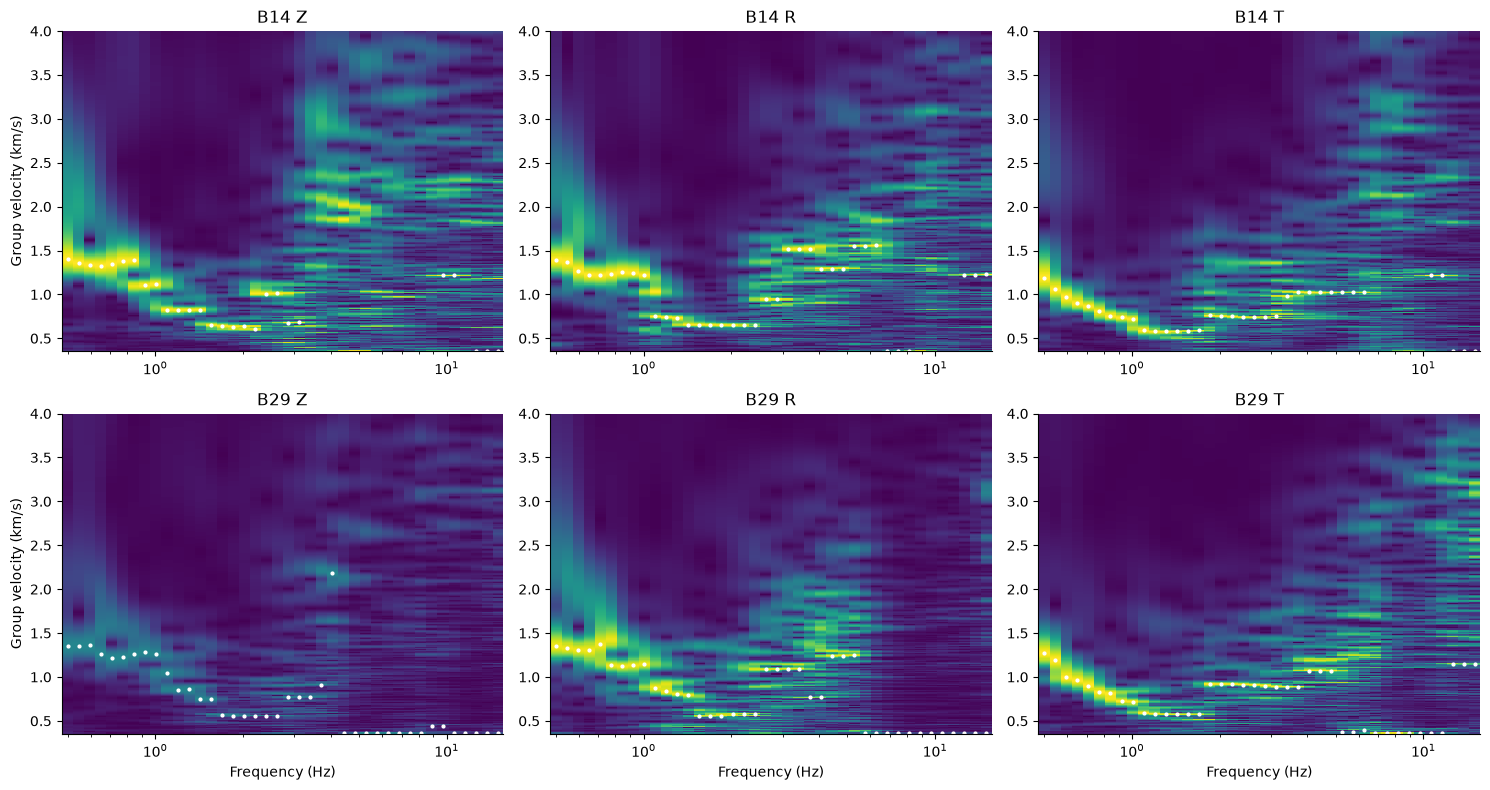

In [5]:
fig, axs = plt.subplots(2, 3, figsize=(15, 8))
for i, sta in enumerate(('B14', 'B29')):
    for j, c in enumerate('ZRT'):
        ax = axs[i, j]
        ax.pcolormesh(F, UG, imgs[(sta, c)], shading='auto', cmap='viridis')
        g = dz[(dz.station == sta) & (dz.comp == c) & dz.ok]
        ax.plot(g.f_hz, g.U_km_s, 'w.', ms=4)
        ax.set(xscale='log', ylim=(0.35, 4), title=f'{sta} {c}')
        if j == 0:
            ax.set_ylabel('Group velocity (km/s)')
        if i == 1:
            ax.set_xlabel('Frequency (Hz)')
fig.tight_layout()
fig.savefig(OUT / 'ftan_ZRT.png', dpi=150, bbox_inches='tight')

### Data curves for the joint fit (0.5–3.4 Hz)

* **Rayleigh:** median of Z at B14, B29, B05 and R at B14, B29.
* **Love:** median of T at B14 and B29, at 0.5–1.8 Hz only. Above 1.8 Hz the transverse ridge jumps to a
  faster branch (0.75–0.92 km/s) that no fundamental-mode Love curve reproduces; it matches the first
  higher Love mode of the fitted models (shown in the figure) and is left out of the fit.
* **H/V:** median of the R/Z ridge-amplitude ratio at B14 and B29. This is a crude ellipticity: the ridges
  may mix modes and include some Love energy, so it is fitted only in fit D.

Uncertainty: the larger of half the range between stations and 7% (25% for H/V).

In [6]:
band = dz[dz.ok & (dz.f_hz <= 3.4)]
def curve(sel, floor):
    g = band[sel].groupby('f_hz').U_km_s.agg(['median', 'min', 'max', 'size'])
    g = g[g['size'] >= 2]
    return g.index.to_numpy(), g['median'].to_numpy() * 1000, np.maximum((g['max'] - g['min']) / 2, floor * g['median']).to_numpy() * 1000
fR, UR, sR = curve(band.comp.isin(['Z', 'R']), 0.07)
fL, UL, sL = curve(band.comp == 'T', 0.07)
fL_all, UL_all, sL_all = fL, UL, sL
k = fL <= 1.8
fL, UL, sL = fL[k], UL[k], sL[k]
amp = dz[(dz.f_hz <= 3.4) & dz.station.isin(['B14', 'B29'])].pivot_table(index='f_hz', columns=['station', 'comp'], values='amp')
hv = np.vstack([amp[(s, 'R')] / amp[(s, 'Z')] for s in ('B14', 'B29')])
fH, HV = amp.index.to_numpy(), np.median(hv, axis=0)
sH = np.maximum(np.abs(hv[0] - hv[1]) / 2, 0.25 * HV)
pd.concat([pd.DataFrame(dict(kind='Rayleigh', f_hz=fR, value=UR, sigma=sR)),
           pd.DataFrame(dict(kind='Love', f_hz=fL, value=UL, sigma=sL)),
           pd.DataFrame(dict(kind='H/V', f_hz=fH, value=HV, sigma=sH))]).to_csv(OUT / 'joint_data.csv', index=False)
STAS = ['B14', 'B29', 'B05']
xP = picks.loc[STAS, 'distance_m'].to_numpy()
tP = picks.loc[STAS, 'first_arrival_s'].to_numpy()
sP = np.sqrt((picks.loc[STAS, 'first_arrival_spread_s'].to_numpy() / 2) ** 2 + 1.0)
print(f'{len(fR)} Rayleigh, {len(fL)} Love (<= 1.8 Hz), {len(fH)} H/V points; resonance {F0_OBS:.2f} +/- {F0_SIG:.2f} Hz')

22 Rayleigh, 15 Love (<= 1.8 Hz), 22 H/V points; resonance 4.92 +/- 0.52 Hz


## 3. Joint model: three layers over a half-space

Parameters $h_1, V_{S1}, h_2, V_{S2}, h_3, V_{S3}, V_{S4}$, with the half-space faster than every layer above
(the layers themselves may be in any order). Bounds: $h_1$ 3–80 m, $h_2$ 5–300 m, $h_3$ 20–600 m,
$V_{S1..3}$ 100–1800 m/s, $V_{S4}$ 700–3000 m/s. Misfit: the sum of mean squared normalised residuals for
Rayleigh, Love and P (fit C), plus H/V (fit D). Each fit is found by differential evolution with five
random seeds; the spread of the five optima shows how well each parameter is determined. The ground
resonance (notebook 28) is not fitted: in trials it conflicted with the surface waves, so the model's
quarter-wavelength S resonance of the top layer is reported for comparison instead.

In [7]:
from scipy.optimize import differential_evolution
RHO = [1800.0, 1950.0, 2100.0, 2250.0]
BND = [(3, 80), (100, 1800), (5, 300), (100, 1800), (20, 600), (100, 1800), (700, 3000)]
cols = ['h1_m', 'vs1_m_s', 'h2_m', 'vs2_m_s', 'h3_m', 'vs3_m_s', 'vs4_m_s']

def model(p):
    h1, v1, h2, v2, h3, v3, v4 = p
    vs = [v1, v2, v3, v4]
    return ([h1, h2, h3, 0.0], [max(1600.0, 1.9 * v) for v in vs], vs, RHO)

def terms(p, use_hv):
    m = model(p)
    R = sw.rayleigh_group(m, fR).ravel()
    L = sw.love_group(m, fL).ravel()
    t = sw.first_arrival_times(m, xP)
    out = dict(rayleigh=np.mean(((R - UR) / sR) ** 2), love=np.mean(((L - UL) / sL) ** 2), P=np.mean(((t - tP) / sP) ** 2))
    if use_hv:
        H = sw.rayleigh_ellipticity(m, fH)
        out['hv'] = np.nanmean(((H - HV) / sH) ** 2)
    return out

def misfit(p, use_hv=False):
    if p[6] <= max(p[1], p[3], p[5]):
        return 1e3
    try:
        v = sum(terms(p, use_hv).values())
    except Exception:
        return 1e3
    return v if np.isfinite(v) else 1e3

FITS = {'C: Rayleigh + Love + P': False, 'D: C + H/V': True}
runs = []
for name, use_hv in FITS.items():
    for seed in range(5):
        r = differential_evolution(misfit, BND, args=(use_hv,), seed=seed, popsize=20, maxiter=120, tol=1e-6, polish=True)
        runs.append(dict(fit=name, seed=seed, misfit=r.fun, **dict(zip(cols, r.x)), **terms(r.x, True)))
runs = pd.DataFrame(runs)
runs['depth_to_halfspace_m'] = runs.h1_m + runs.h2_m + runs.h3_m
runs['f0_top_layer_hz'] = runs.vs1_m_s / (4 * runs.h1_m)
runs.to_csv(OUT / 'joint_ensemble.csv', index=False)
fits = {name: runs[runs.fit == name].sort_values('misfit').iloc[0][cols].to_numpy(float) for name in FITS}
for name, b in fits.items():
    m = model(b)
    pd.DataFrame(dict(thickness_m=m[0], vp_m_s=m[1], vs_m_s=m[2], rho_kg_m3=m[3]),
                 index=['layer 1', 'layer 2', 'layer 3', 'half-space']).to_csv(OUT / f'best_model_{name[0]}.csv')
show = runs.groupby('fit')[['misfit', 'rayleigh', 'love', 'P', 'hv'] + cols + ['depth_to_halfspace_m', 'f0_top_layer_hz']]
display(show.median().T.round(2).join(show.min().T.round(0), rsuffix=' min').join(show.max().T.round(0), rsuffix=' max'))
print(f'observed ground resonance {F0_OBS:.2f} Hz')

fit,C: Rayleigh + Love + P,D: C + H/V,C: Rayleigh + Love + P min,D: C + H/V min,C: Rayleigh + Love + P max,D: C + H/V max
misfit,2.78,5.21,3.0,5.0,3.0,5.0
rayleigh,0.85,0.87,1.0,1.0,1.0,1.0
love,0.40,0.98,0.0,1.0,0.0,1.0
P,1.53,1.54,2.0,2.0,2.0,2.0
hv,5.00,1.82,5.0,2.0,5.0,2.0
h1_m,49.71,30.09,49.0,30.0,50.0,31.0
vs1_m_s,556.85,330.26,556.0,329.0,559.0,333.0
h2_m,114.55,102.96,114.0,100.0,115.0,105.0
vs2_m_s,767.81,781.04,767.0,777.0,769.0,786.0
h3_m,218.77,173.85,217.0,172.0,220.0,175.0


observed ground resonance 4.92 Hz


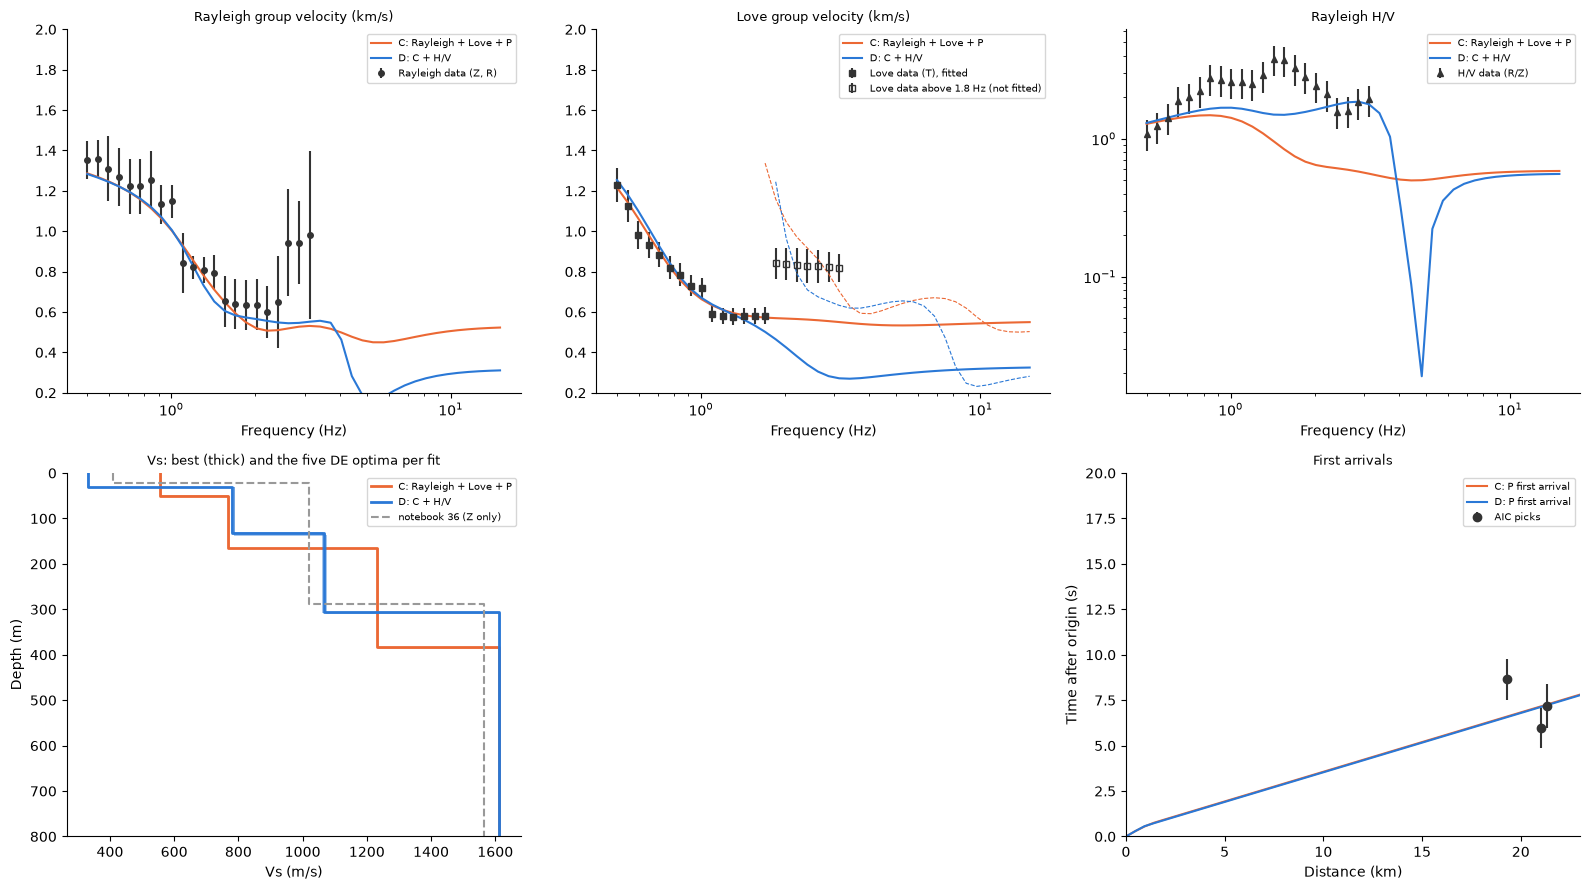

In [8]:
fh = np.geomspace(0.5, 15, 40)
COL = {'C: Rayleigh + Love + P': '#eb6834', 'D: C + H/V': '#2a78d6'}
fig, axs = plt.subplots(2, 3, figsize=(16, 9))
ax = axs[0, 0]
ax.errorbar(fR, UR / 1000, yerr=sR / 1000, fmt='o', color='#333333', ms=4, label='Rayleigh data (Z, R)')
ax2 = axs[0, 1]
ax2.errorbar(fL, UL / 1000, yerr=sL / 1000, fmt='s', color='#333333', ms=4, label='Love data (T), fitted')
hi = fL_all > 1.8
ax2.errorbar(fL_all[hi], UL_all[hi] / 1000, yerr=sL_all[hi] / 1000, fmt='s', mfc='none', color='#333333', ms=4, label='Love data above 1.8 Hz (not fitted)')
ax3 = axs[0, 2]
ax3.errorbar(fH, HV, yerr=sH, fmt='^', color='#333333', ms=4, label='H/V data (R/Z)')
for k, b in fits.items():
    m = model(b)
    ax.plot(fh, sw.rayleigh_group(m, fh).ravel() / 1000, color=COL[k], label=k)
    Lm = sw.love_group(m, fh, nmodes=2)
    ax2.plot(fh, Lm[:, 0] / 1000, color=COL[k], label=k)
    ax2.plot(fh, Lm[:, 1] / 1000, '--', color=COL[k], lw=0.8)
    ax3.plot(fh, sw.rayleigh_ellipticity(m, fh), color=COL[k], label=k)
for a, t in ((ax, 'Rayleigh group velocity (km/s)'), (ax2, 'Love group velocity (km/s)'), (ax3, 'Rayleigh H/V')):
    a.set(xscale='log', xlabel='Frequency (Hz)', title=t)
    a.legend(fontsize=7)
ax.set_ylim(0.2, 2); ax2.set_ylim(0.2, 2); ax3.set_yscale('log')
ax = axs[1, 0]
zmax = 800
def prof(p):
    h1, v1, h2, v2, h3, v3, v4 = p
    z = [0, h1, h1, h1 + h2, h1 + h2, h1 + h2 + h3, h1 + h2 + h3, zmax]
    return z, [v1, v1, v2, v2, v3, v3, v4, v4]
for k in FITS:
    for _, r in runs[runs.fit == k].iterrows():
        z, v = prof(r[cols].to_numpy(float)); ax.plot(v, z, color=COL[k], lw=0.6, alpha=0.5)
    z, v = prof(fits[k]); ax.plot(v, z, color=COL[k], lw=2, label=k)
nb36 = pd.read_csv(cfg.OUT_DIR / '36_velocity_model' / 'best_model_B.csv', index_col=0)
zz = np.r_[0, np.cumsum(nb36.thickness_m.values[:-1])]
ax.step(np.r_[nb36.vs_m_s.values, nb36.vs_m_s.values[-1]], np.r_[zz, zmax], where='pre', color='#999999', ls='--', label='notebook 36 (Z only)')
ax.set(ylim=(zmax, 0), xlabel='Vs (m/s)', ylabel='Depth (m)', title='Vs: best (thick) and the five DE optima per fit')
ax.legend(fontsize=7)
axs[1, 1].set_visible(False)
ax = axs[1, 2]
xx = np.linspace(0, 23000, 50)
for k, b in fits.items():
    ax.plot(xx / 1000, sw.first_arrival_times(model(b), xx), color=COL[k], label=f'{k[:1]}: P first arrival')
ax.errorbar(xP / 1000, tP, yerr=sP, fmt='o', color='#333333', label='AIC picks')
ax.set(xlabel='Distance (km)', ylabel='Time after origin (s)', title='First arrivals', xlim=(0, 23), ylim=(0, 20))
ax.legend(fontsize=7)
for a in fig.axes:
    a.title.set_fontsize(9)
fig.tight_layout()
fig.savefig(OUT / 'joint_model.png', dpi=150, bbox_inches='tight')

## What this shows

* **B20's horizontals are one signal.** HH1 and HH2 correlate at 0.9999 all year. Together with its noisy
  vertical and reversed coupling sign, this points to a fault in B20's Trillium or its cabling. Worth
  checking in the field.
* **Orientation (B14, B29).** A single event does not fix it precisely; the principal axes vary between
  windows. The best-defined Rayleigh band and the dispersion test both support the nominal installation
  (H1 north, H2 east). With it, the radial dispersion matches the vertical's, and the transverse shows a
  separate Love curve that is nearly identical at B14 and B29. A precise orientation from many sources at
  known pads (the 2026 launches) is a follow-up.
* **Love waves are strong.** The transverse ridge is about 1.2–1.3 times the radial at 0.5–3 Hz, so the
  explosion (or scattering near it) put much of its surface-wave energy into SH. Love group velocity falls
  from 1.2–1.3 km/s at 0.5 Hz to 0.58 km/s at 1.2–1.7 Hz. Above 1.8 Hz the ridge jumps to 0.75–0.92 km/s,
  close to the models' first higher Love mode.
* **Rayleigh H/V** along the fundamental ridge rises from about 1 at 0.5 Hz to 3–4 at 1.4–1.7 Hz.
* **Joint model.** Fitting Rayleigh and Love together removes much of the trade-off seen with the verticals
  alone (notebook 36), and both fits agree on the main structure:
  * a surface layer 30–50 m thick at Vs 330–560 m/s;
  * a layer about 100–115 m thick at Vs 770–780 m/s;
  * a layer 170–220 m thick at Vs 1070–1230 m/s;
  * a half-space at Vs ≈ 1610 m/s (Vp ≈ 3.1 km/s) from 305–385 m depth.

  This is a velocity gradient through the upper 300–400 m, rather than the single Vs ≈ 1 km/s block of
  notebook 36. Misfits are 0.85 (Rayleigh) and 0.40 (Love) for fit C; fit D brings H/V from 5.0 to 1.8
  at little cost elsewhere, but under-predicts the H/V peak's height.
* **Not explained.**
  * The ground resonance at 4.9 Hz does not match these models' top-layer S resonance (2.7–2.8 Hz). It may
    be a thinner, slower layer than surface waves at ≤ 3.4 Hz can see, consistent with the Anastasia
    Formation/surficial-aquifer boundary near 9 m found by Woo et al. (2024).
  * The P picks still scatter by more than any 1D model allows.
* **Agreement across five optimiser seeds** shows that the optimum is well defined for this
  parameterisation. It is not a data uncertainty: the difference between fits C and D is the better guide
  to what the data cannot separate.